**1. Importing the dependencies**

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pickle

**2. Data Loading & Understanding**

In [103]:
# read the csv data to a pandas dataframe
df = pd.read_csv(r"C:\Users\LENOVO\Desktop\ML\train.csv")

Initial Inspection

In [104]:
df.shape

(800, 22)

In [105]:
df.head(8)

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38.172746,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,0,47.750517,m,?,no,no,India,no,2.255185,18 and more,Self,0
2,3,1,1,1,1,1,1,1,1,1,1,7.380373,m,White-European,no,yes,United States,no,14.851484,18 and more,Self,1
3,4,0,0,0,0,0,0,0,0,0,0,23.561927,f,?,no,no,United States,no,2.276617,18 and more,Self,0
4,5,0,0,0,0,0,0,0,0,0,0,43.205790,m,?,no,no,South Africa,no,-4.777286,18 and more,Self,0
5,6,1,0,0,0,0,1,0,0,1,1,31.527964,m,Middle Eastern,no,no,Jordan,no,9.562117,18 and more,Self,0
6,7,1,0,0,0,0,0,1,1,1,0,28.427971,f,Pasifika,no,no,United Kingdom,no,7.984569,18 and more,Self,0
7,8,1,1,1,1,1,1,1,0,1,1,26.484494,m,Black,no,yes,United States,no,13.237898,18 and more,Self,1


In [6]:
df.tail(8)

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,...,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
792,793,1,0,0,0,0,0,0,0,0,...,m,?,no,no,Bolivia,no,9.403804,18 and more,Self,0
793,794,0,0,0,0,0,0,0,0,0,...,m,?,no,no,United Kingdom,no,9.777375,18 and more,Self,0
794,795,0,1,0,0,1,0,0,1,0,...,m,?,no,no,India,no,9.592719,18 and more,Self,0
795,796,0,1,0,0,0,0,0,0,1,...,m,Hispanic,no,no,New Zealand,no,12.999501,18 and more,Self,0
796,797,0,1,1,0,0,1,0,1,1,...,m,White-European,no,no,Cyprus,no,13.561518,18 and more,Self,0
797,798,0,0,0,0,0,0,0,0,0,...,m,South Asian,yes,no,New Zealand,no,2.653177,18 and more,Self,0
798,799,0,0,0,0,0,0,0,0,0,...,f,?,no,no,Canada,no,9.069342,18 and more,Self,0
799,800,0,1,0,0,0,0,0,0,0,...,f,?,no,no,United Arab Emirates,yes,2.243304,18 and more,Self,0


In [106]:
# display all columns of a dataframe
pd.set_option('display.max_columns', None)

In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               800 non-null    int64  
 1   A1_Score         800 non-null    int64  
 2   A2_Score         800 non-null    int64  
 3   A3_Score         800 non-null    int64  
 4   A4_Score         800 non-null    int64  
 5   A5_Score         800 non-null    int64  
 6   A6_Score         800 non-null    int64  
 7   A7_Score         800 non-null    int64  
 8   A8_Score         800 non-null    int64  
 9   A9_Score         800 non-null    int64  
 10  A10_Score        800 non-null    int64  
 11  age              800 non-null    float64
 12  gender           800 non-null    object 
 13  ethnicity        800 non-null    object 
 14  jaundice         800 non-null    object 
 15  austim           800 non-null    object 
 16  contry_of_res    800 non-null    object 
 17  used_app_before 

In [108]:
# convert age column datatype to integer
df["age"] = df["age"].astype(int)

In [109]:
df.head(5)

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,18 and more,Self,0
2,3,1,1,1,1,1,1,1,1,1,1,7,m,White-European,no,yes,United States,no,14.851484,18 and more,Self,1
3,4,0,0,0,0,0,0,0,0,0,0,23,f,?,no,no,United States,no,2.276617,18 and more,Self,0
4,5,0,0,0,0,0,0,0,0,0,0,43,m,?,no,no,South Africa,no,-4.777286,18 and more,Self,0


In [110]:
for col in df.columns:
  numerical_features = ["ID", "age", "result"]
  if col not in numerical_features:
    print(col, df[col].unique())
    print("-"*50)

A1_Score [1 0]
--------------------------------------------------
A2_Score [0 1]
--------------------------------------------------
A3_Score [1 0]
--------------------------------------------------
A4_Score [0 1]
--------------------------------------------------
A5_Score [1 0]
--------------------------------------------------
A6_Score [0 1]
--------------------------------------------------
A7_Score [1 0]
--------------------------------------------------
A8_Score [0 1]
--------------------------------------------------
A9_Score [1 0]
--------------------------------------------------
A10_Score [1 0]
--------------------------------------------------
gender ['f' 'm']
--------------------------------------------------
ethnicity ['?' 'White-European' 'Middle Eastern ' 'Pasifika' 'Black' 'Others'
 'Hispanic' 'Asian' 'Turkish' 'South Asian' 'Latino' 'others']
--------------------------------------------------
jaundice ['no' 'yes']
--------------------------------------------------
austim

In [111]:
# dropping ID & age_desc column
df = df.drop(columns=["ID", "age_desc"])

In [112]:
df.shape

(800, 20)

In [113]:
df.head(5)

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,Self,0
2,1,1,1,1,1,1,1,1,1,1,7,m,White-European,no,yes,United States,no,14.851484,Self,1
3,0,0,0,0,0,0,0,0,0,0,23,f,?,no,no,United States,no,2.276617,Self,0
4,0,0,0,0,0,0,0,0,0,0,43,m,?,no,no,South Africa,no,-4.777286,Self,0


In [114]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

In [115]:
df["contry_of_res"].unique()

array(['Austria', 'India', 'United States', 'South Africa', 'Jordan',
       'United Kingdom', 'Brazil', 'New Zealand', 'Canada', 'Kazakhstan',
       'United Arab Emirates', 'Australia', 'Ukraine', 'Iraq', 'France',
       'Malaysia', 'Viet Nam', 'Egypt', 'Netherlands', 'Afghanistan',
       'Oman', 'Italy', 'AmericanSamoa', 'Bahamas', 'Saudi Arabia',
       'Ireland', 'Aruba', 'Sri Lanka', 'Russia', 'Bolivia', 'Azerbaijan',
       'Armenia', 'Serbia', 'Ethiopia', 'Sweden', 'Iceland', 'Hong Kong',
       'Angola', 'China', 'Germany', 'Spain', 'Tonga', 'Pakistan', 'Iran',
       'Argentina', 'Japan', 'Mexico', 'Nicaragua', 'Sierra Leone',
       'Czech Republic', 'Niger', 'Romania', 'Cyprus', 'Belgium',
       'Burundi', 'Bangladesh'], dtype=object)

In [116]:
# define the mapping dictionary for country names
mapping = {
    "Viet Nam": "Vietnam",
    "AmericanSamoa": "United States",
    "Hong Kong": "China"
}

# repalce value in the country column
df["contry_of_res"] = df["contry_of_res"].replace(mapping)

In [117]:
df["contry_of_res"].unique()

array(['Austria', 'India', 'United States', 'South Africa', 'Jordan',
       'United Kingdom', 'Brazil', 'New Zealand', 'Canada', 'Kazakhstan',
       'United Arab Emirates', 'Australia', 'Ukraine', 'Iraq', 'France',
       'Malaysia', 'Vietnam', 'Egypt', 'Netherlands', 'Afghanistan',
       'Oman', 'Italy', 'Bahamas', 'Saudi Arabia', 'Ireland', 'Aruba',
       'Sri Lanka', 'Russia', 'Bolivia', 'Azerbaijan', 'Armenia',
       'Serbia', 'Ethiopia', 'Sweden', 'Iceland', 'China', 'Angola',
       'Germany', 'Spain', 'Tonga', 'Pakistan', 'Iran', 'Argentina',
       'Japan', 'Mexico', 'Nicaragua', 'Sierra Leone', 'Czech Republic',
       'Niger', 'Romania', 'Cyprus', 'Belgium', 'Burundi', 'Bangladesh'],
      dtype=object)

In [118]:
# taget class distribution
df["Class/ASD"].value_counts()

Class/ASD
0    639
1    161
Name: count, dtype: int64

**Insights:**
1. missing values in ethnicity & relation
2. age_desc column has only 1 unique value. so it is removed as it is not important for prediction
3. fixed country names
4. identified class imbalance in the target column

**3. Exploratory Data Analysis (EDA)**

In [119]:
df.shape

(800, 20)

In [120]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

In [121]:
df.head(5)

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,Self,0
2,1,1,1,1,1,1,1,1,1,1,7,m,White-European,no,yes,United States,no,14.851484,Self,1
3,0,0,0,0,0,0,0,0,0,0,23,f,?,no,no,United States,no,2.276617,Self,0
4,0,0,0,0,0,0,0,0,0,0,43,m,?,no,no,South Africa,no,-4.777286,Self,0


In [122]:
df.describe()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,result,Class/ASD
count,800.000000,800.000000,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,0.560000,0.530000,0.450000,0.41500,0.395000,0.303750,0.397500,0.508750,0.495000,0.617500,27.963750,8.537303,0.201250
std,0.496697,0.499411,0.497805,0.49303,0.489157,0.460164,0.489687,0.500236,0.500288,0.486302,16.329827,4.807676,0.401185
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,-6.137748,0.000000
25%,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,5.306575,0.000000
50%,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,24.000000,9.605299,0.000000
75%,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,35.250000,12.514484,0.000000
max,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,89.000000,15.853126,1.000000


**Univariate Analysis**

Numerical Columns:
- age
- result

In [123]:
# set the desired theme
sns.set_theme(style="darkgrid")

Distribution Plots

In [124]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [125]:
try:
    # Load the data and ensure the 'age' column is treated as numeric
    df = pd.read_csv(r"C:\Users\LENOVO\Desktop\ML\train.csv")
    df['age'] = pd.to_numeric(df['age'], errors='coerce')
    # Assuming 'Class/ASD' is the target column for coloring
    if 'Class/ASD' not in df.columns:
        raise KeyError("Class/ASD column not found in train.csv.")

    df = df.dropna(subset=['age', 'Class/ASD'])
    # Clean the class labels for better legend readability
    df['Class/ASD'] = df['Class/ASD'].astype(str).replace({'0': 'No ASD', '1': 'ASD Positive'})

except (FileNotFoundError, KeyError) as e:
    print(f"Warning: {e}. Using mock data for demonstration.")
    # Create a mock DataFrame for demonstration if file is missing or column is missing
    df = pd.DataFrame({
        'age': [25, 30, 30, 35, 40, 40, 45, 50, 50, 50, 55, 60, 65, 70, 22, 33, 58],
        'Class/ASD': ['No ASD', 'No ASD', 'ASD Positive', 'No ASD', 'ASD Positive', 'No ASD', 'No ASD', 'ASD Positive', 'No ASD', 'No ASD', 'ASD Positive', 'No ASD', 'No ASD', 'ASD Positive', 'No ASD', 'ASD Positive', 'No ASD']
})

# Calculate descriptive statistics
age_mean = df["age"].mean()
age_median = df["age"].median()

print(f"--- Summary Statistics ---")
print(f"Mean Age: {age_mean:.2f}")
print(f"Median Age: {age_median:.2f}")
print("-" * 30)

--- Summary Statistics ---
Mean Age: 28.45
Median Age: 24.85
------------------------------


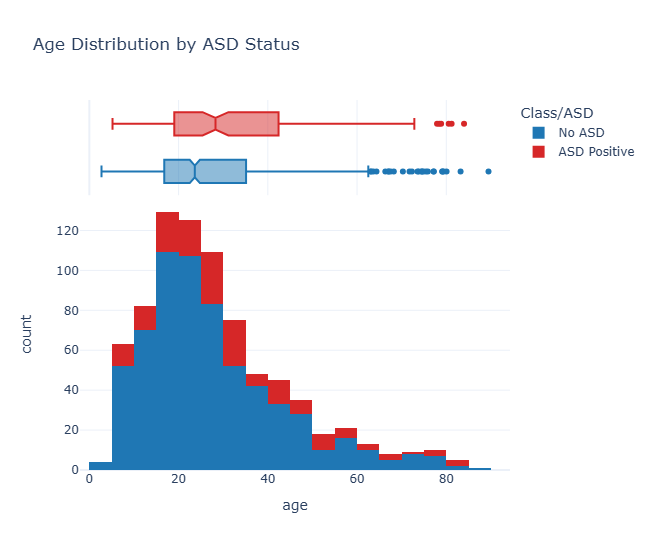

In [126]:
# 1. Create the histogram using Plotly Express, coloring by the Class/ASD column
fig = px.histogram(
    df,
    x="age",
    title="Age Distribution by ASD Status",
    template="plotly_white",
    # Use 'Class/ASD' for color to show stacked distribution
    color="Class/ASD",
    # Define color scheme
    color_discrete_map={'No ASD': '#1f77b4', 'ASD Positive': '#d62728'},
    # Use 'stack' for barmode to easily see the totals and subgroups
    barmode='stack',
    # Add a box plot on the margin, now colored by the same groups
    marginal="box",
    nbins=30,
    height=550
)
fig.show()

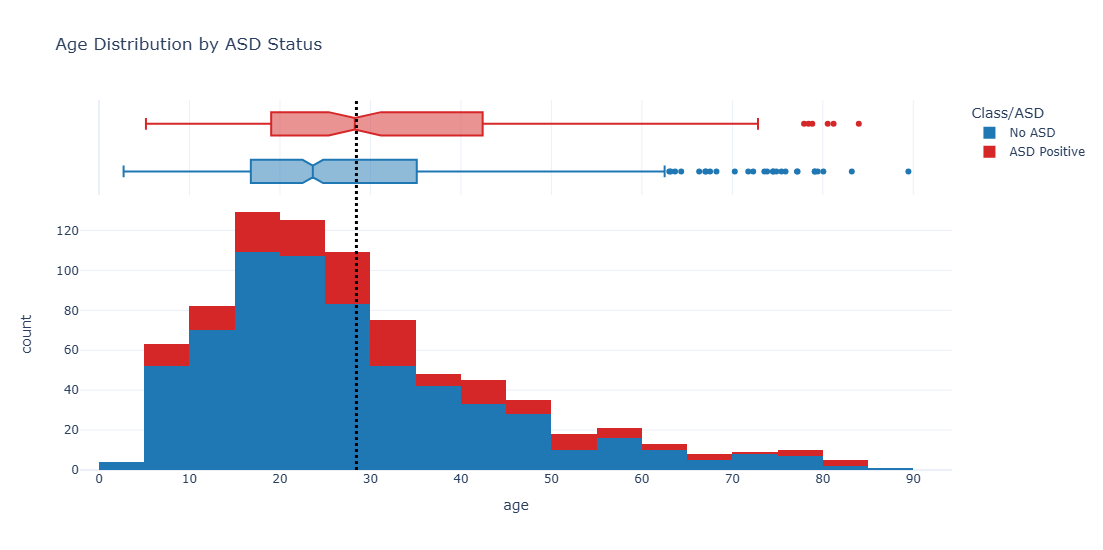

In [31]:
# 2. Add Mean Line as a vertical shape (Black Dotted)
fig.add_shape(
    type="line",
    x0=age_mean, y0=0,
    x1=age_mean, y1=1,
    line=dict(color="black", width=3, dash="dot"),
    xref='x',
    yref='paper'
)
fig.show()

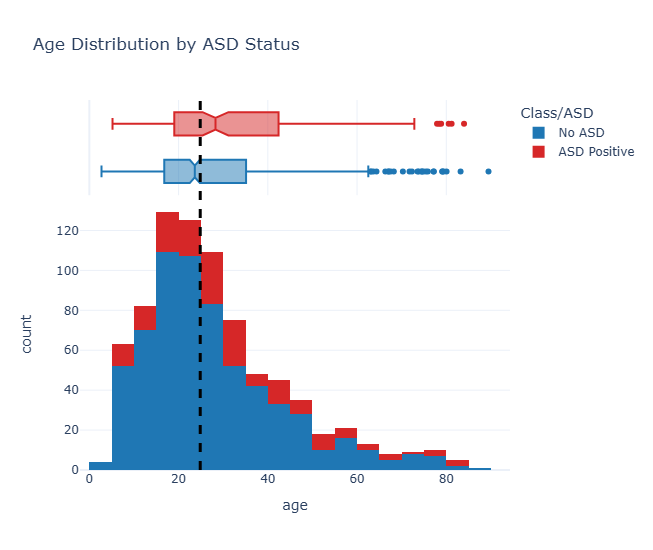

In [127]:
# 3. Add Median Line as a vertical shape (Black Dashed)
fig.add_shape(
    type="line",
    x0=age_median, y0=0,
    x1=age_median, y1=1,
    line=dict(color="black", width=3, dash="dash"),
    xref='x',
    yref='paper'
)
fig.show()

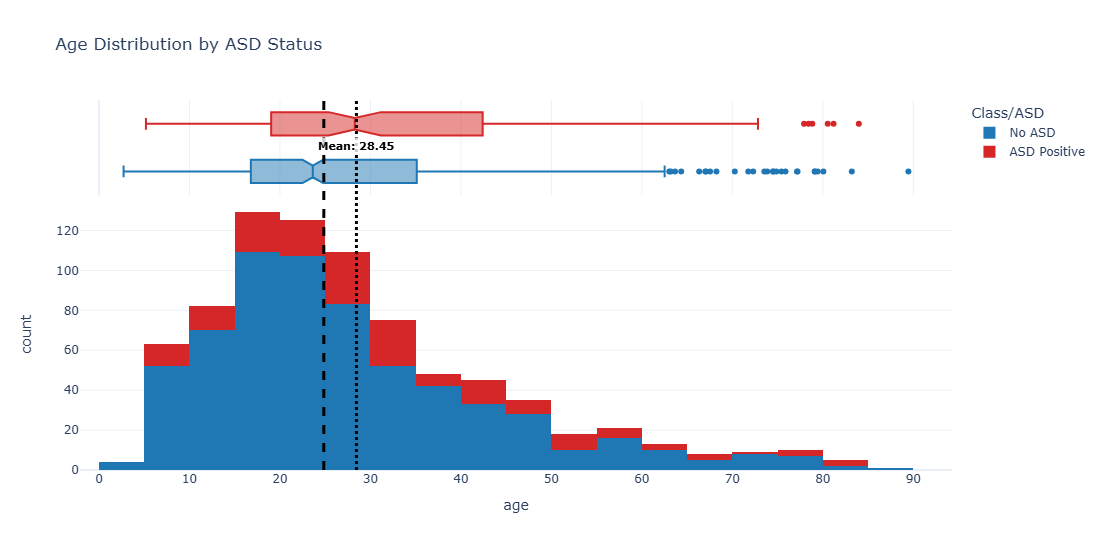

In [34]:
#4. Add Mean annotation (label)
fig.add_annotation(
    x=age_mean,
    y=0.9,
    yref="paper",
    text=f"<b>Mean: {age_mean:.2f}</b>",
    showarrow=False,
    font=dict(color="black", size=11),
    bgcolor="rgba(255, 255, 255, 0.8)"
)

fig.show()

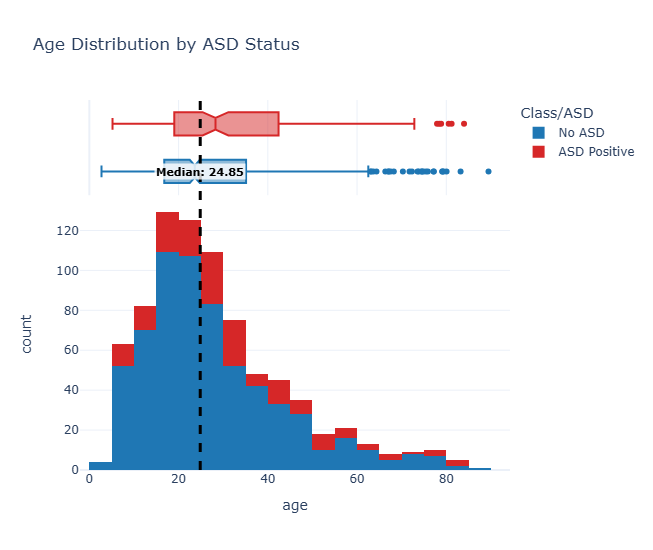

In [128]:
fig.add_annotation(
    x=age_median,
    y=0.83,
    yref="paper",
    text=f"<b>Median: {age_median:.2f}</b>",  # bold using HTML
    showarrow=False,
    font=dict(color="black", size=11),
    bgcolor="rgba(255, 255, 255, 0.8)"
)
fig.show()

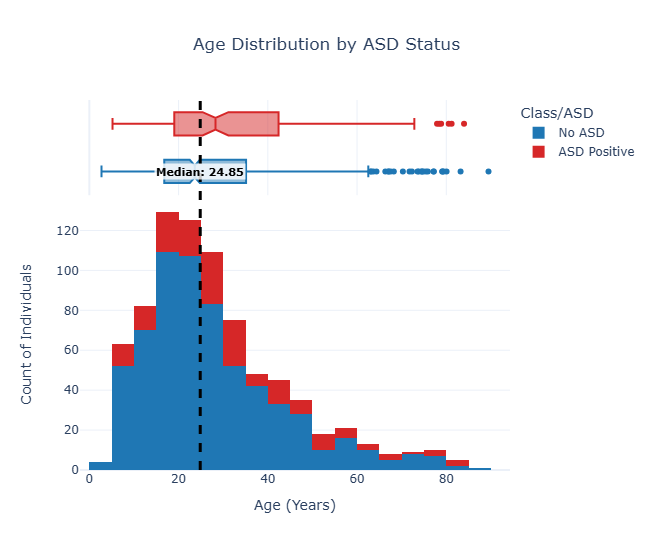

In [129]:
# 6. Final layout enhancements
fig.update_layout(
    xaxis_title="Age (Years)",
    yaxis_title="Count of Individuals",
    title_x=0.5,
    hovermode="x unified", # Shows combined tooltips on hover
    showlegend=True
)

# Display the interactive plot
fig.show()

C:\Users\LENOVO\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.



Mean of result: 8.54
Median of result: 9.61


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_16900\1425471179.py:32: UserWarning:

Glyph 128202 (\N{BAR CHART}) missing from current font.

C:\Users\LENOVO\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning:

Glyph 128202 (\N{BAR CHART}) missing from current font.



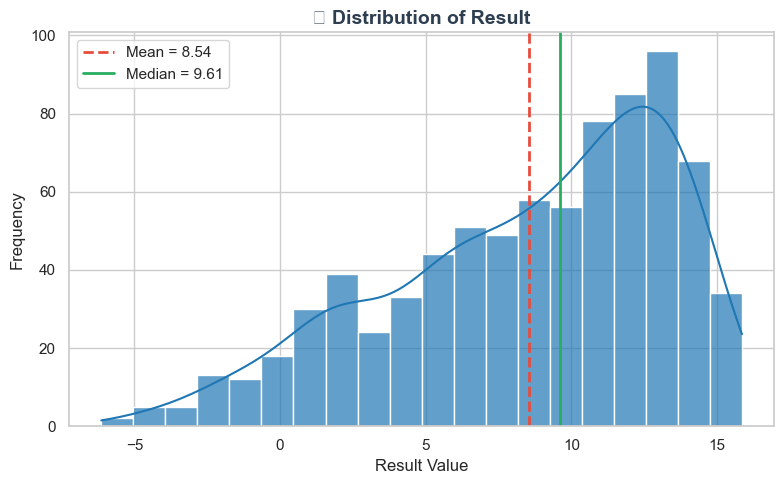

In [130]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Load the data
df = pd.read_csv(r"C:\Users\LENOVO\Desktop\ML\train.csv")

# Set aesthetic style
sns.set(style="whitegrid")

# Create the histogram with color and KDE
plt.figure(figsize=(8,5))
sns.histplot(df["result"], kde=True, color="#1f77b4", bins=20, alpha=0.7)

# Calculate mean and median
result_mean = df["result"].mean()
result_median = df["result"].median()

# Print values
print(f"Mean of result: {result_mean:.2f}")
print(f"Median of result: {result_median:.2f}")

# Add vertical lines for mean and median
plt.axvline(result_mean, color="#e74c3c", linestyle="--", linewidth=2, label=f"Mean = {result_mean:.2f}")
plt.axvline(result_median, color="#27ae60", linestyle="-", linewidth=2, label=f"Median = {result_median:.2f}")

# Titles and labels
plt.title("📊 Distribution of Result", fontsize=14, fontweight='bold', color="#2c3e50")
plt.xlabel("Result Value", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

**Box plots for identifying outliers in the numerical columns**

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_16900\67264218.py:21: UserWarning:

Glyph 128230 (\N{PACKAGE}) missing from current font.

C:\Users\LENOVO\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning:

Glyph 128230 (\N{PACKAGE}) missing from current font.



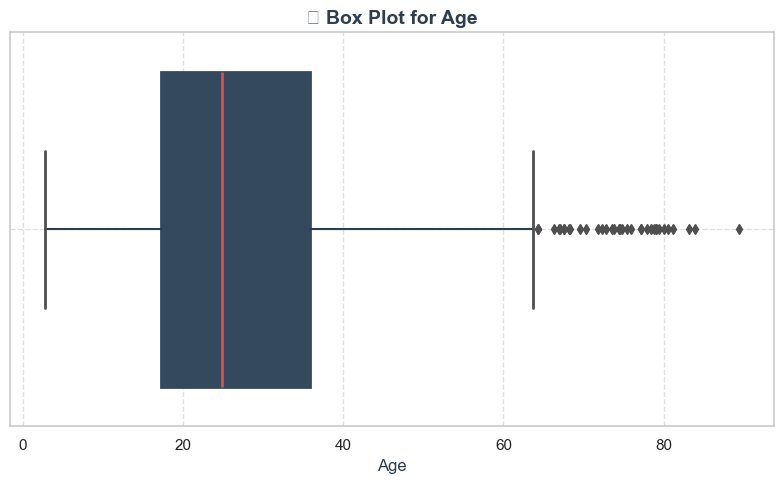

In [131]:
sns.set(style="whitegrid")

# Create the box plot
plt.figure(figsize=(8,5))
sns.boxplot(
    x=df["age"],
    color="#58a4b0",  # soft teal color
    fliersize=5,      # size of outlier points
    linewidth=2,
    boxprops=dict(facecolor="#a7c7e7", color="#34495e"),  # box fill + edge color
    medianprops=dict(color="#e74c3c", linewidth=2),       # median line color
    whiskerprops=dict(color="#2c3e50", linewidth=1.5)     # whisker color
)

# Add title and labels
plt.title("📦 Box Plot for Age", fontsize=14, fontweight='bold', color="#2c3e50")
plt.xlabel("Age", fontsize=12, color="#2c3e50")

# Show grid and layout
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

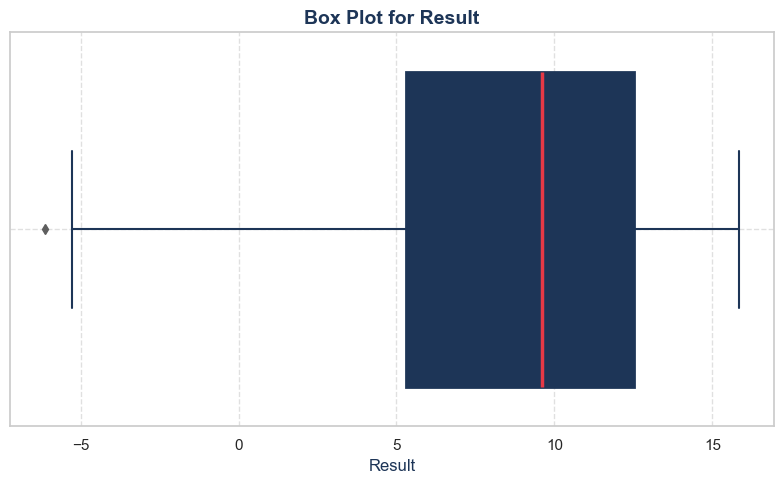

In [132]:
sns.set(style="whitegrid")

# Create the box plot
plt.figure(figsize=(8,5))
sns.boxplot(
    x=df["result"],
    color="#76b5c5",   # soothing teal
    fliersize=5,       # size of outlier points
    linewidth=2,
    boxprops=dict(facecolor="#a8dadc", color="#1d3557"),   # box color & border
    medianprops=dict(color="#e63946", linewidth=2.5),      # median line (red)
    whiskerprops=dict(color="#1d3557", linewidth=1.5),     # whisker color
    capprops=dict(color="#1d3557", linewidth=1.5)          # caps on whiskers
)

# Add title and labels
plt.title("Box Plot for Result", fontsize=14, fontweight='bold', color="#1d3557")
plt.xlabel("Result", fontsize=12, color="#1d3557")

# Grid and layout
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [133]:
# count the outliers using IQR method
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
age_outliers = df[(df["age"] < lower_bound) | (df["age"] > upper_bound)]

In [134]:
print("Length of Age_outliers:",len(age_outliers))

Length of Age_outliers: 35


In [135]:
# count the outliers using IQR method
Q1 = df["result"].quantile(0.25)
Q3 = df["result"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
result_outliers = df[(df["result"] < lower_bound) | (df["result"] > upper_bound)]

In [136]:
print("Length of Result_outliers:",len(result_outliers))

Length of Result_outliers: 1


**Univariate analysis of Categorical columns**

In [137]:
df.columns

Index(['ID', 'A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score',
       'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age',
       'gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res',
       'used_app_before', 'result', 'age_desc', 'relation', 'Class/ASD'],
      dtype='object')

In [138]:
import matplotlib.pyplot as plt
import seaborn as sns
import random

categorical_columns = [
    'A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
    'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'gender', 'ethnicity',
    'jaundice', 'austim', 'contry_of_res', 'used_app_before', 'relation'
]

palettes = ['Set2', 'coolwarm', 'husl', 'cubehelix', 'viridis', 'Spectral', 'pastel', 'mako']

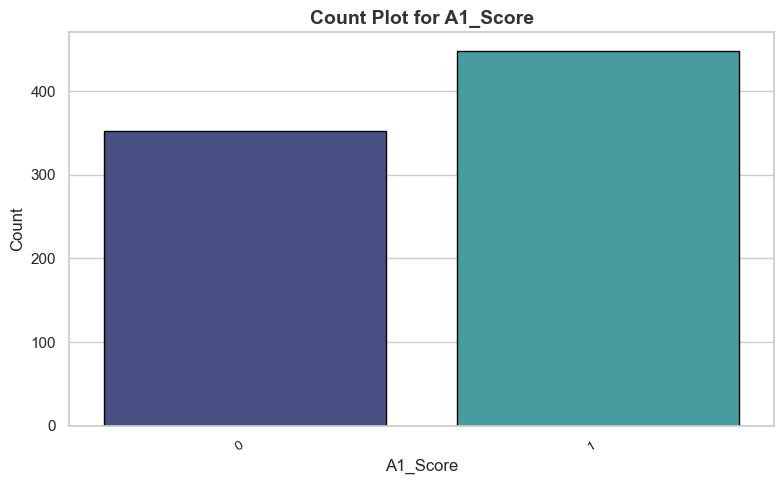

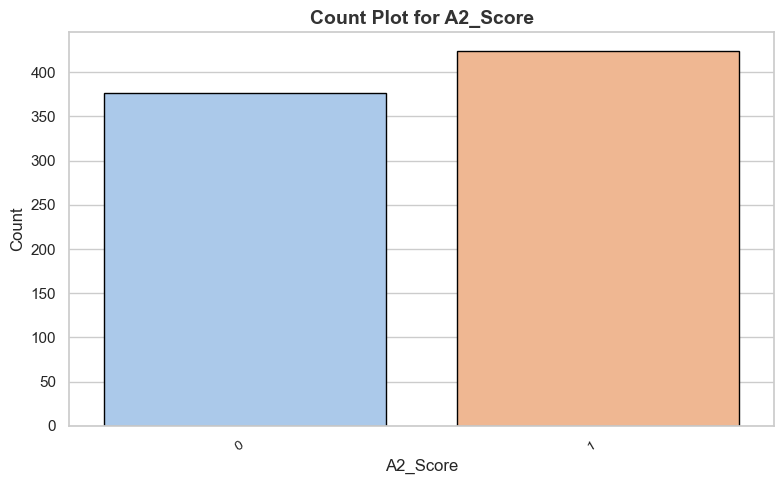

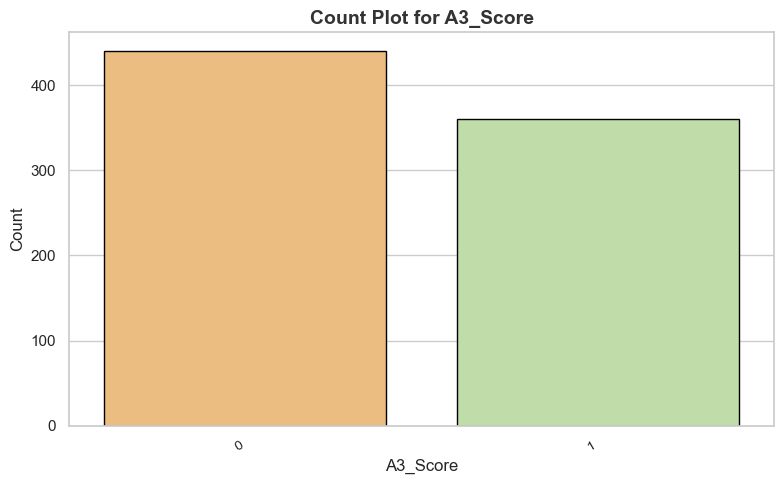

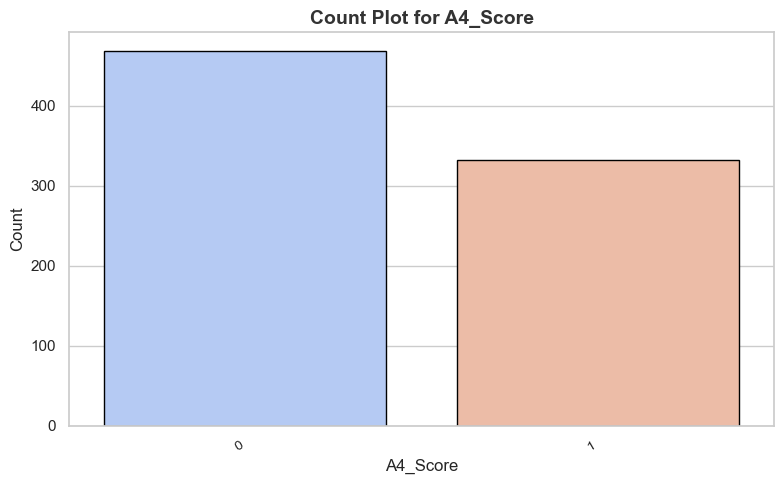

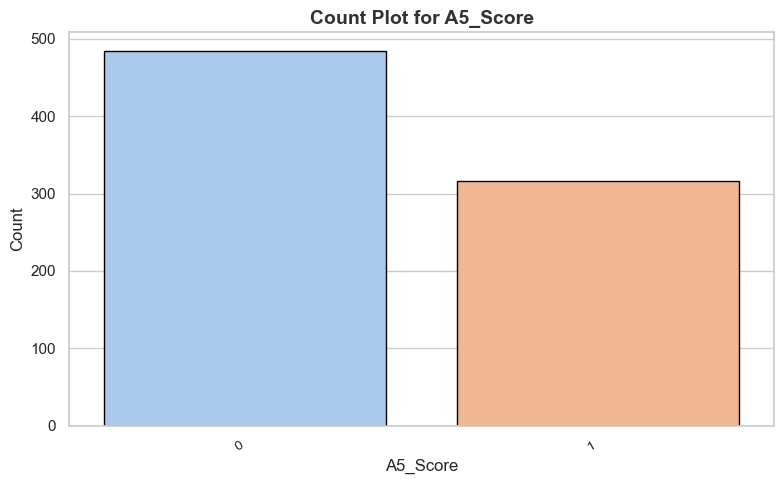

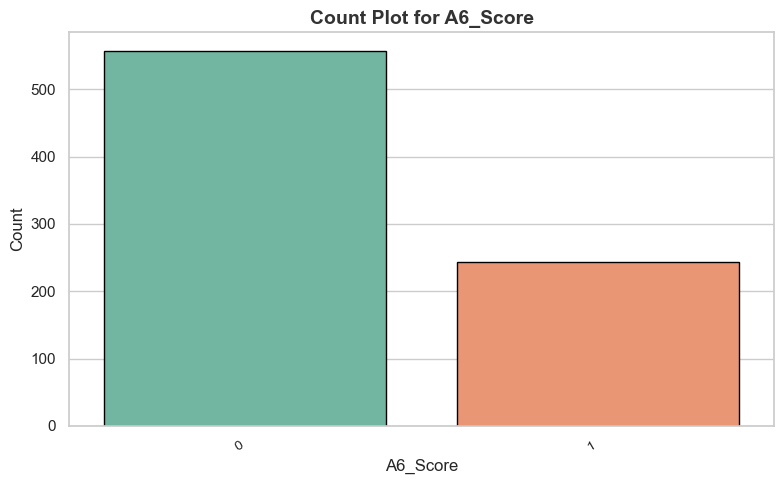

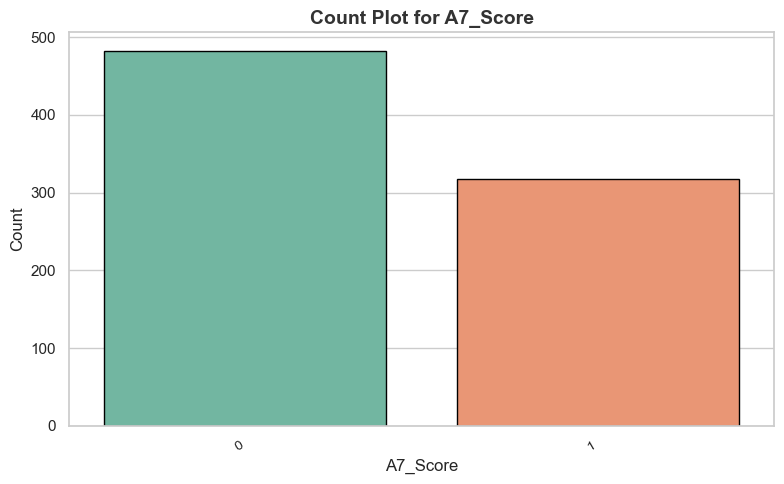

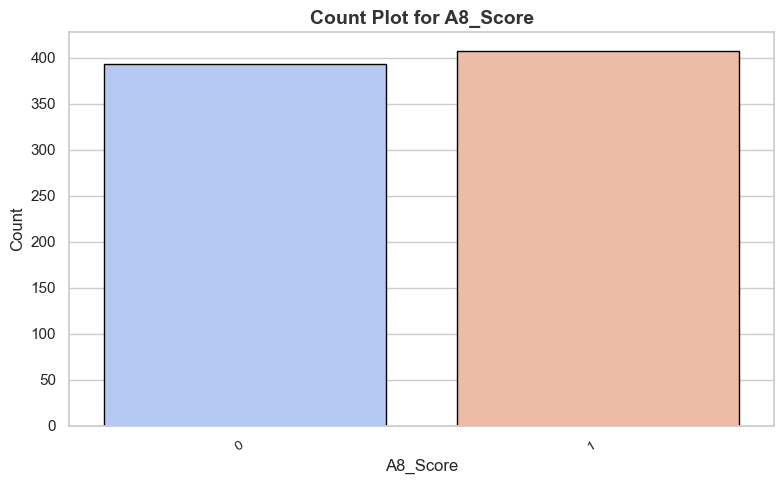

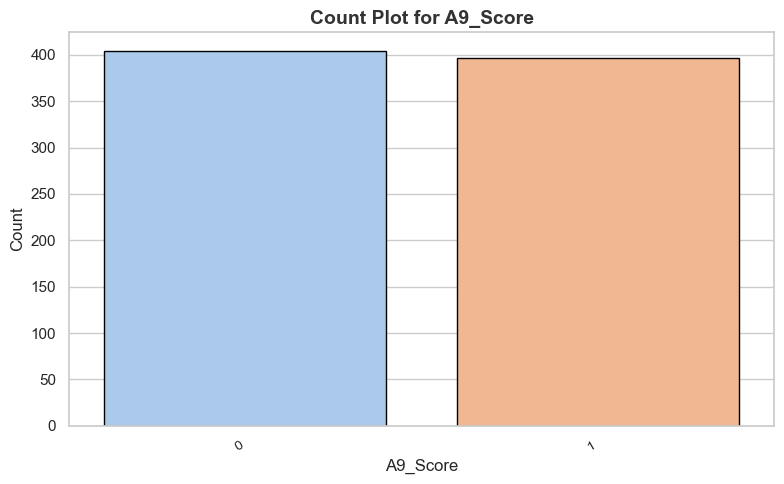

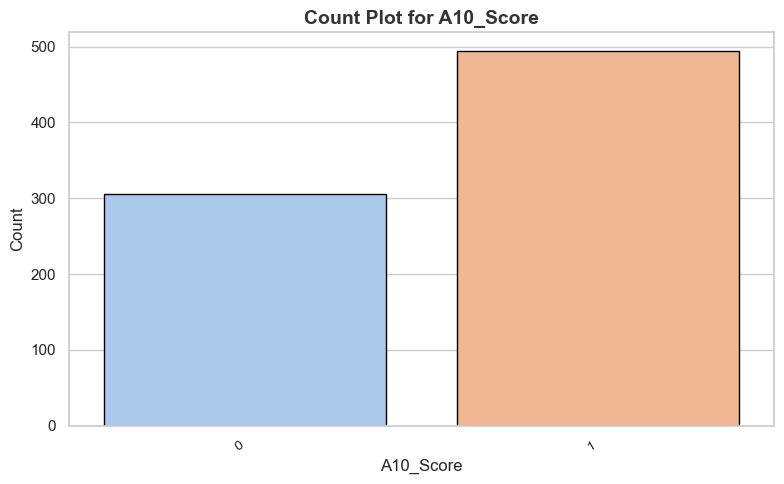

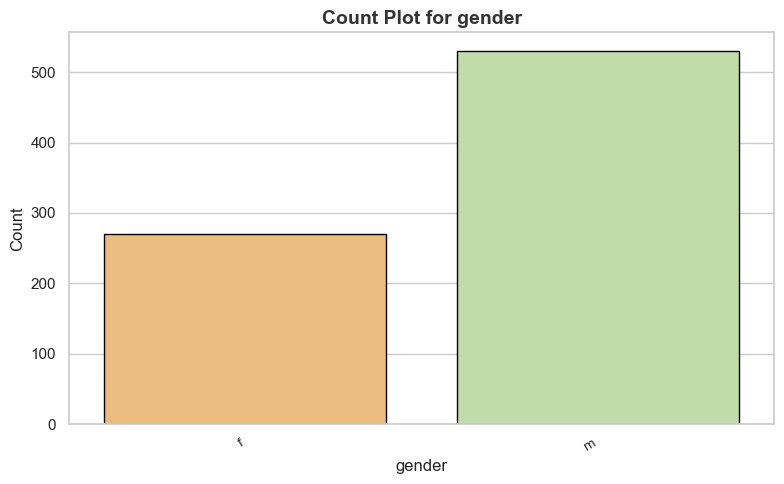

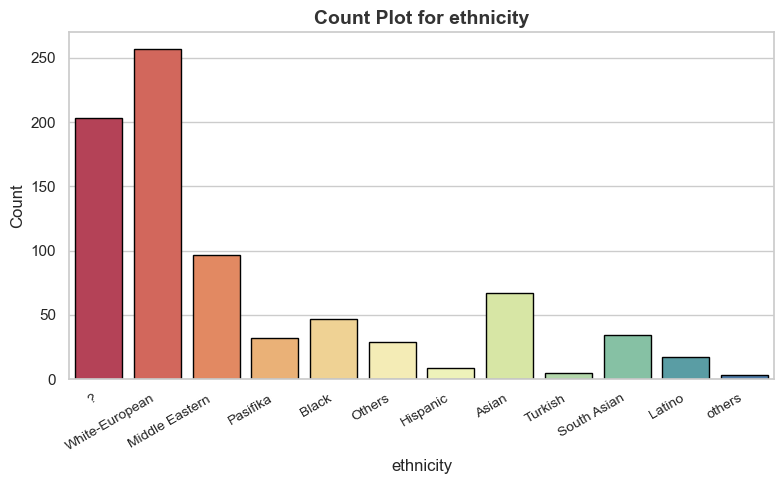

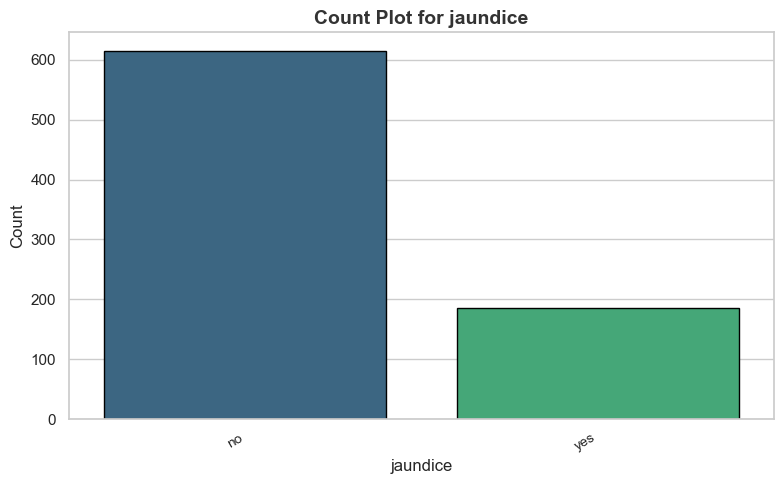

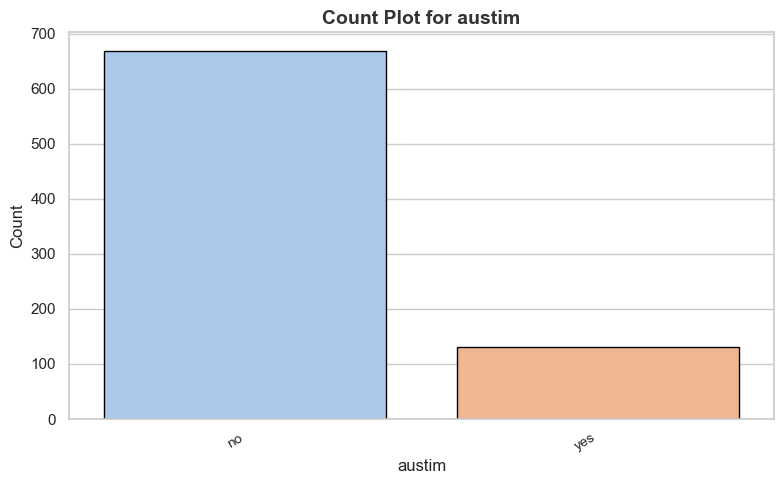

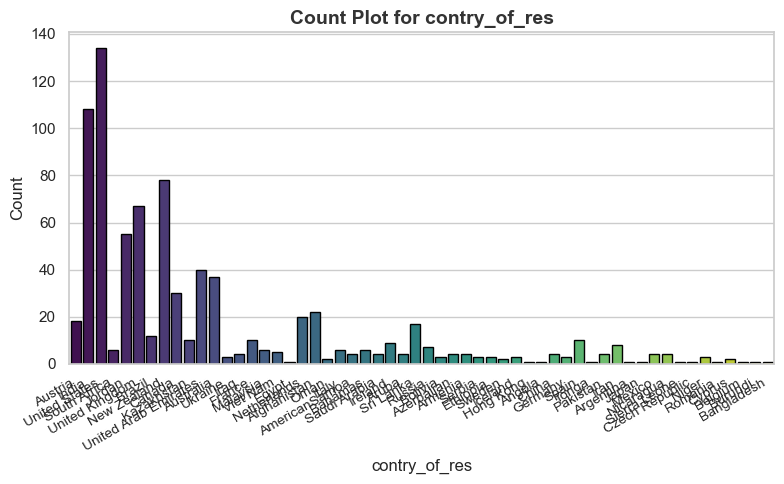

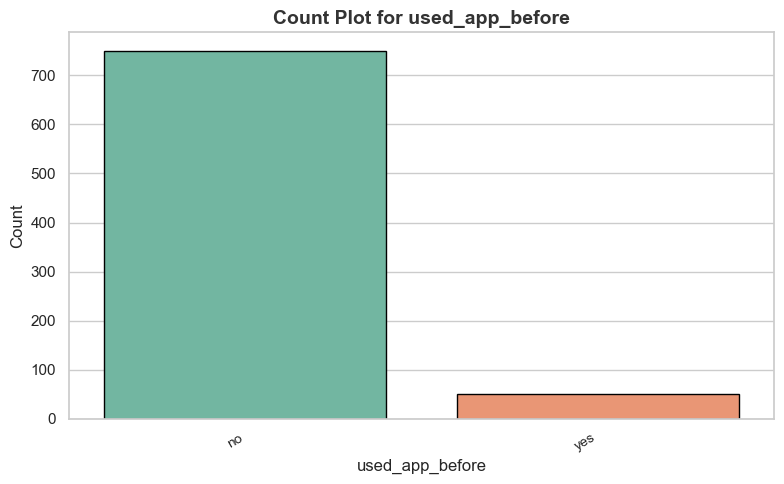

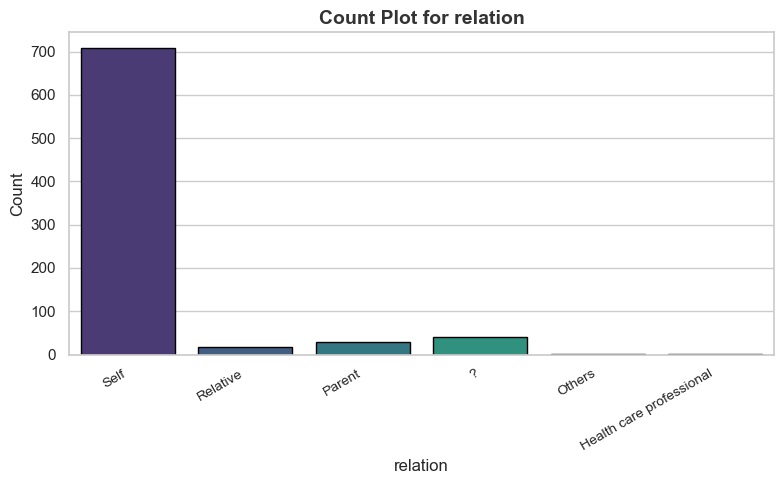

In [139]:
for col in categorical_columns:
    plt.figure(figsize=(8, 5))

    palette_choice = random.choice(palettes)

    sns.countplot(data=df, x=col, palette=palette_choice, edgecolor='black')

    plt.title(f"Count Plot for {col}", fontsize=14, fontweight='bold', color='#333')
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Count", fontsize=12)


    plt.xticks(rotation=30, ha='right', fontsize=10)
    plt.tight_layout()

    plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_16900\1454794181.py:27: UserWarning:

Glyph 129504 (\N{BRAIN}) missing from current font.

C:\Users\LENOVO\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning:

Glyph 129504 (\N{BRAIN}) missing from current font.



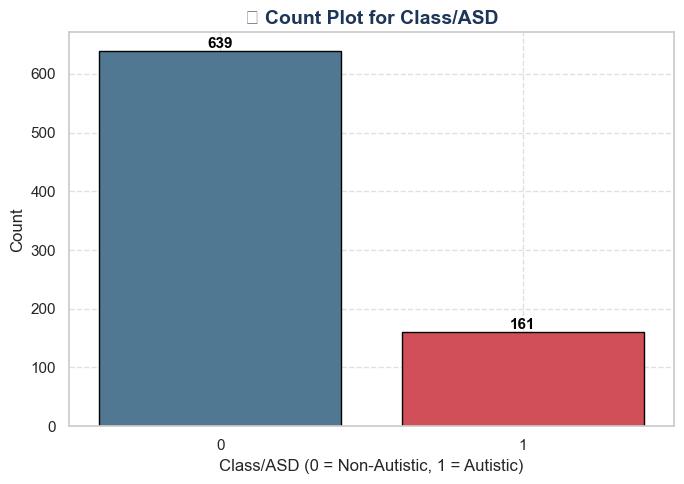

In [54]:
sns.set(style="whitegrid")

# Create figure
plt.figure(figsize=(7,5))

# Create countplot with custom colors
ax = sns.countplot(
    x=df["Class/ASD"],
    palette=["#457b9d", "#e63946"],   # blue for Non-ASD, red for ASD
    edgecolor="black"
)

# Add labels on bars
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=11, color='black', fontweight='bold'
    )

# Titles and labels
plt.title("🧠 Count Plot for Class/ASD", fontsize=14, fontweight='bold', color="#1d3557")
plt.xlabel("Class/ASD (0 = Non-Autistic, 1 = Autistic)", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [140]:
df["Class/ASD"].value_counts()

Class/ASD
0    639
1    161
Name: count, dtype: int64

**handle missing values in ethnicity and relation column**

In [141]:
df["ethnicity"] = df["ethnicity"].replace({"?": "Others", "others": "Others"})
df["relation"] = df["relation"].replace({"?": "Others", "Relative": "Others", "Parent": "Others", "Health care professional": "Others"})

In [142]:
df["ethnicity"].unique()

array(['Others', 'White-European', 'Middle Eastern ', 'Pasifika', 'Black',
       'Hispanic', 'Asian', 'Turkish', 'South Asian', 'Latino'],
      dtype=object)

In [143]:
df["relation"].unique()

array(['Self', 'Others'], dtype=object)

In [144]:
df["relation"] = df["relation"].replace(
    {"?": "Others",
     "Relative": "Others",
     "Parent": "Others",
     "Health care professional": "Others"}
)

In [145]:
df["relation"].unique()

array(['Self', 'Others'], dtype=object)

In [146]:
df.head(3)

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38.172746,f,Others,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,0,47.750517,m,Others,no,no,India,no,2.255185,18 and more,Self,0
2,3,1,1,1,1,1,1,1,1,1,1,7.380373,m,White-European,no,yes,United States,no,14.851484,18 and more,Self,1


**Label Encoding**

In [147]:
# identify columns with "object" data type
object_columns = df.select_dtypes(include=["object"]).columns

In [148]:
print(object_columns)

Index(['gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res',
       'used_app_before', 'age_desc', 'relation'],
      dtype='object')


In [149]:
# initialize a dictionary to store the encoders
encoders = {}

# apply label encoding and store the encoders
for column in object_columns:
  label_encoder = LabelEncoder()
  df[column] = label_encoder.fit_transform(df[column])
  encoders[column] = label_encoder   # saving the encoder for this column


# save the encoders as a pickle file
with open("encoders.pkl", "wb") as f:
  pickle.dump(encoders, f)

In [150]:
encoders

{'gender': LabelEncoder(),
 'ethnicity': LabelEncoder(),
 'jaundice': LabelEncoder(),
 'austim': LabelEncoder(),
 'contry_of_res': LabelEncoder(),
 'used_app_before': LabelEncoder(),
 'age_desc': LabelEncoder(),
 'relation': LabelEncoder()}

In [151]:
df.head(3)

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38.172746,0,5,0,0,7,0,6.351166,0,1,0
1,2,0,0,0,0,0,0,0,0,0,0,47.750517,1,5,0,0,25,0,2.255185,0,1,0
2,3,1,1,1,1,1,1,1,1,1,1,7.380373,1,9,0,1,54,0,14.851484,0,1,1


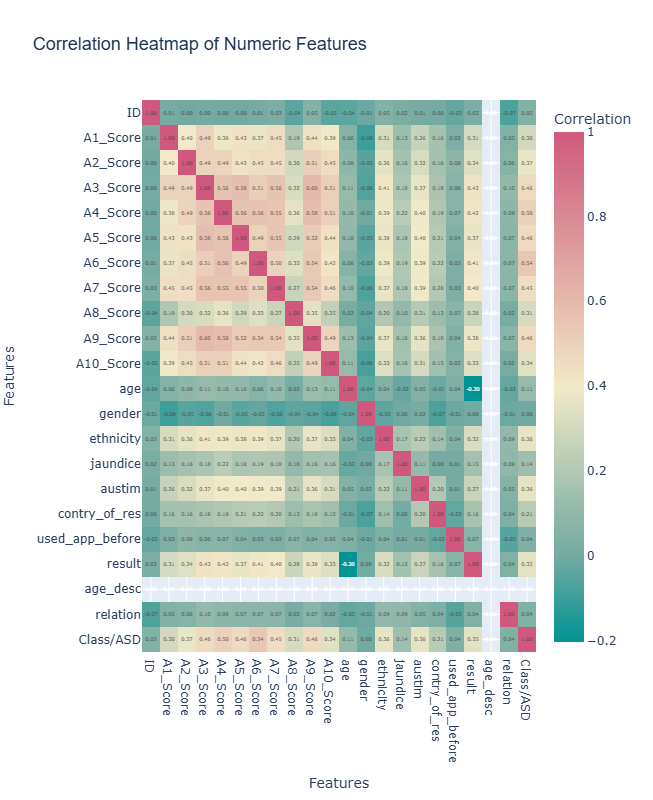

In [152]:
# Select only numeric columns for correlation
numeric_df = df.select_dtypes(include=["number"])

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Create interactive heatmap using Plotly
fig = px.imshow(
    corr_matrix,
    text_auto=".2f",  # show values inside cells
    color_continuous_scale="Tealrose",  # blue-red color scale
    title="Correlation Heatmap of Numeric Features",
    aspect="auto"
)

# Update layout for better readability
fig.update_layout(
    width=800,
    height=800,
    title_font=dict(size=18, family="Arial", color="#1d3557"),
    xaxis_title="Features",
    yaxis_title="Features",
    coloraxis_colorbar=dict(title="Correlation"),
)

# Show interactive plot
fig.show()

**Bivariate Analysis**

**Insights from EDA:**

- There are few outliers in the numerical columns (age, results)
- There is a class imbalance in the target column
- There is a class imbalance in the categorical features
- We don't have any highly correlated column
- performed label encoding and saved the encoders

**4. Data preprocessing**

**Handling outliers**

In [153]:
# function to replace the outliers with median
def replace_outliers_with_median(df, column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  median = df[column].median()

  # replace outliers with median value
  df[column] = df[column].apply(lambda x: median if x < lower_bound or x > upper_bound else x)

  return df

In [154]:
# replace outliers in the "age" column
df = replace_outliers_with_median(df, "age")

# replace outliers in the "result" column
df = replace_outliers_with_median(df, "result")

In [155]:
df.head(3)

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38.172746,0,5,0,0,7,0,6.351166,0,1,0
1,2,0,0,0,0,0,0,0,0,0,0,47.750517,1,5,0,0,25,0,2.255185,0,1,0
2,3,1,1,1,1,1,1,1,1,1,1,7.380373,1,9,0,1,54,0,14.851484,0,1,1


In [156]:
df.shape

(800, 22)

**Train Test Split**

In [157]:
df.columns

Index(['ID', 'A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score',
       'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age',
       'gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res',
       'used_app_before', 'result', 'age_desc', 'relation', 'Class/ASD'],
      dtype='object')

In [158]:
X = df.drop(columns=["Class/ASD"])
y = df["Class/ASD"]

In [159]:
print(X)

      ID  A1_Score  A2_Score  A3_Score  A4_Score  A5_Score  A6_Score  \
0      1         1         0         1         0         1         0   
1      2         0         0         0         0         0         0   
2      3         1         1         1         1         1         1   
3      4         0         0         0         0         0         0   
4      5         0         0         0         0         0         0   
..   ...       ...       ...       ...       ...       ...       ...   
795  796         0         1         0         0         0         0   
796  797         0         1         1         0         0         1   
797  798         0         0         0         0         0         0   
798  799         0         0         0         0         0         0   
799  800         0         1         0         0         0         0   

     A7_Score  A8_Score  A9_Score  A10_Score        age  gender  ethnicity  \
0           1         0         1          1  38.172746  

In [160]:
print(y)

0      0
1      0
2      1
3      0
4      0
      ..
795    0
796    0
797    0
798    0
799    0
Name: Class/ASD, Length: 800, dtype: int64


In [161]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [162]:
print(y_train.shape)
print(y_test.shape)

(640,)
(160,)


In [163]:
y_train.value_counts()

Class/ASD
0    511
1    129
Name: count, dtype: int64

In [164]:
y_test.value_counts()

Class/ASD
0    128
1     32
Name: count, dtype: int64

**SMOTE (Synthetic Minority Oversampling technique)**

In [165]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [166]:
print(y_train_smote.shape)

(1022,)


In [167]:
print(y_train_smote.value_counts())

Class/ASD
0    511
1    511
Name: count, dtype: int64


In [168]:
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

scaler = StandardScaler()
X_train_smote = scaler.fit_transform(X_train_smote)
X_test = scaler.transform(X_test)
X_scaled = scaler.fit_transform(X)

sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_scaled, y)

print("After balancing:", np.bincount(y_res))

After balancing: [639 639]


**5. Model Training**

In [169]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# dictionary of classifiers
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

In [170]:
# dictionary to store the cross validation results
cv_scores = {}

# perform 5-fold cross validation for each model
for model_name, model in models.items():
  print(f"Training {model_name} with default parameters...")
  scores = cross_val_score(model, X_train_smote, y_train_smote, cv=5, scoring="accuracy")
  cv_scores[model_name] = scores
  print(f"{model_name} Cross-Validation Accuracy: {np.mean(scores):.2f}")
  print("-"*50)

Training Decision Tree with default parameters...
Decision Tree Cross-Validation Accuracy: 0.84
--------------------------------------------------
Training Random Forest with default parameters...
Random Forest Cross-Validation Accuracy: 0.91
--------------------------------------------------
Training XGBoost with default parameters...
XGBoost Cross-Validation Accuracy: 0.91
--------------------------------------------------


In [171]:
cv_scores

{'Decision Tree': array([0.7804878 , 0.83414634, 0.8872549 , 0.8627451 , 0.85784314]),
 'Random Forest': array([0.88292683, 0.89756098, 0.93627451, 0.92156863, 0.89705882]),
 'XGBoost': array([0.89268293, 0.89756098, 0.92156863, 0.93627451, 0.89705882])}

**6. Model Selection & Hyperparameter Tuning**

In [172]:
# Initializing models
decision_tree = DecisionTreeClassifier(random_state=42)
random_forest = RandomForestClassifier(random_state=42)
xgboost_classifier = XGBClassifier(random_state=42)

In [173]:
# Hyperparameter grids for RandomizedSearchCV
param_grid_dt = {
    "criterion": ["gini", "entropy"],
    "max_depth": [10, 20, 30, 50],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}
param_grid_rf = {
    "n_estimators": [100, 200, 500],
    "max_depth": [10, 20, 30],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "bootstrap": [True, False]
}
param_grid_xgb = {
    "n_estimators": [200, 300, 500],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1, 0.2],
    "subsample": [0.5, 0.7, 1.0],
    "colsample_bytree": [0.5, 0.7, 1.0]
}

In [174]:
# hyperparameter tunig for 3 tree based models

# the below steps can be automated by using a for loop or by using a pipeline

# perform RandomizedSearchCV for each model
random_search_dt = RandomizedSearchCV(estimator=decision_tree, param_distributions=param_grid_dt, n_iter=10, cv=5, scoring="accuracy", random_state=42)
random_search_rf = RandomizedSearchCV(estimator=random_forest, param_distributions=param_grid_rf, n_iter=10, cv=5, scoring="accuracy", random_state=42)
random_search_xgb = RandomizedSearchCV(estimator=xgboost_classifier, param_distributions=param_grid_xgb, n_iter=10, cv=5, scoring="accuracy", random_state=42)


In [175]:
# fit the models
random_search_dt.fit(X_train_smote, y_train_smote)
random_search_rf.fit(X_train_smote, y_train_smote)
random_search_xgb.fit(X_train_smote, y_train_smote)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constrain...
                                           max_leaves=None,
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   param_distributions={'colsample_bytree': [0.5, 0.7, 1.0],
                                        'learning_rate': [0.05, 0.1, 0.2],
                                        'max_depth': [4, 6, 8],
                                        'n_estimators': [200, 300, 500],
                                        'subsample': [0.5, 0.7, 1.0]},
                   random_state=42, scoring='accuracy')

In [176]:
# Get the model with best score

best_model = None
best_score = 0

# Check if random_search_dt was successfully executed
if 'random_search_dt' in locals() and random_search_dt.best_score_ > best_score:
  best_model = random_search_dt.best_estimator_
  best_score = random_search_dt.best_score_

# Check if random_search_rf was successfully executed
if 'random_search_rf' in locals() and random_search_rf.best_score_ > best_score:
  best_model = random_search_rf.best_estimator_
  best_score = random_search_rf.best_score_

# Check if random_search_xgb was successfully executed
if 'random_search_xgb' in locals() and random_search_xgb.best_score_ > best_score:
  best_model = random_search_xgb.best_estimator_
  best_score = random_search_xgb.best_score_

In [177]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier(
    estimators=[
        ('dt', random_search_dt.best_estimator_),
        ('rf', random_search_rf.best_estimator_),
        ('xgb', random_search_xgb.best_estimator_)
    ],
    voting='soft'   # or 'hard'
)

# Train the voting model
voting_model.fit(X_train_smote, y_train_smote)

VotingClassifier(estimators=[('dt',
                              DecisionTreeClassifier(criterion='entropy',
                                                     max_depth=30,
                                                     random_state=42)),
                             ('rf',
                              RandomForestClassifier(bootstrap=False,
                                                     max_depth=30,
                                                     n_estimators=500,
                                                     random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=1.0, device=None,
                                            early...
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.2, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=6,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=500, n_jobs=None,
                                            num_parallel_tree=None, ...))],
                 voting='soft')

In [178]:
# print information about the voting model since it's used for evaluation
print(f"Voting Model: {voting_model}")

# Assuming you have already calculated the accuracy score for the voting model
# If not, you would need to calculate it first:
# from sklearn.metrics import accuracy_score
# y_pred_voting = voting_model.predict(X_test)
# voting_accuracy = accuracy_score(y_test, y_pred_voting)
# print(f"Voting Model Accuracy: {voting_accuracy:.2f}")

Voting Model: VotingClassifier(estimators=[('dt',
                              DecisionTreeClassifier(criterion='entropy',
                                                     max_depth=30,
                                                     random_state=42)),
                             ('rf',
                              RandomForestClassifier(bootstrap=False,
                                                     max_depth=30,
                                                     n_estimators=500,
                                                     random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=1.0, device=None,
                                   

In [179]:
# save the best model
with open("best_model.pkl", "wb") as f:
  pickle.dump(best_model, f)

In [180]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    eval_metric='logloss'
)
rf = RandomForestClassifier(n_estimators=300, random_state=42)
lr = LogisticRegression(max_iter=1000, random_state=42)

voting_model = VotingClassifier(
    estimators=[('xgb', xgb), ('rf', rf), ('lr', lr)],
    voting='soft'
)

voting_model.fit(X_res, y_res)

VotingClassifier(estimators=[('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=0.9, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric='logloss',
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_con...
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=6,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=400, n_jobs=None,
                                            num_parallel_tree=None, ...)),
                             ('rf',
                              RandomForestClassifier(n_estimators=300,
                                                     random_state=42)),
                             ('lr',
                              LogisticRegression(max_iter=1000,
                                                 random_state=42))],
                 voting='soft')

**7. Evaluation**

In [181]:
# Evaluate the voting model
y_pred = voting_model.predict(X_test) # Changed best_model to voting_model

accuracy = accuracy_score(y_test, y_pred)

print("\n Final Accuracy:", accuracy)
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


 Final Accuracy: 0.8625

Confusion Matrix:
 [[107  21]
 [  1  31]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.84      0.91       128
           1       0.60      0.97      0.74        32

    accuracy                           0.86       160
   macro avg       0.79      0.90      0.82       160
weighted avg       0.91      0.86      0.87       160

